# BAB 11 - PEMBELAJARAN MENDALAM (DEEP LEARNING 1)
## Praktikum 11.2: Membuat Model Klasifikasi 2 Kelas & Pengujian Citra Uji (tes1.jpeg & tes2.jpeg)

**Capaian Pembelajaran:**
1. Memisahkan modul *training* (`train.py`) dan modul *inference/testing* (`test.py`).
2. Melatih model klasifikasi biner citra Mobil dan Motor dengan batch size kecil (2).
3. Menyimpan model terlatih ke dalam format Keras (`model_motor_mobil.keras`).
4. Menguji citra baru (`tes1.jpeg` dan `tes2.jpeg`) menggunakan `load_model()` dan memetakan nilai probabilitas output Sigmoid ke label kelas.

In [1]:
# ==========================================================
# SETUP GOOGLE COLAB: GPU & AUTO-DOWNLOAD DATASET
# ==========================================================
import os
import tensorflow as tf

# 1. Cek Ketersediaan GPU (T4 GPU di Google Colab)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'>>> [AKTIF] Akselerasi GPU Terdeteksi: {gpus[0].name}')
    print('>>> Model akan dilatih dengan kecepatan tinggi di GPU!')
else:
    print('>>> [PERINGATAN] GPU belum aktif. Masuk menu: Runtime -> Ubah jenis runtime -> Pilih T4 GPU.')

# 2. Otomatisasi Unduh & Ekstrak Dataset Lengkap
if not os.path.exists('Dataset 1') or not os.path.exists('Dataset 2') or not os.path.exists('Dataset 3'):
    print('\n>>> Mengunduh dataset praktikum dari server CDN...')
    os.system('wget -q https://files.catbox.moe/po8wfa.zip -O dataset_modul11.zip')
    os.system('unzip -q -o dataset_modul11.zip')
    print('>>> [SUKSES] Dataset 1, Dataset 2, dan Dataset 3 berhasil diekstrak dan siap digunakan!')
else:
    print('>>> [INFO] Folder dataset sudah lengkap di direktori kerja.')


>>> [PERINGATAN] GPU belum aktif. Masuk menu: Runtime -> Ubah jenis runtime -> Pilih T4 GPU.
>>> [INFO] Folder dataset sudah lengkap di direktori kerja.


### Bagian 1: Pelatihan Model (Train Module)
Membaca dataset citra mobil dan motor, melatih arsitektur CNN 2 blok konvolusi ber-padding same, dan menyimpan model.

In [2]:
import tensorflow as tf
import numpy as np
import random
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

dataset_dir = "Dataset 2/Dataset" if os.path.exists("Dataset 2/Dataset") else "Dataset"

datagen = ImageDataGenerator(rescale=1./255)
train_data = datagen.flow_from_directory(
    dataset_dir,
    target_size=(224, 224),
    batch_size=2,
    class_mode="binary",
    shuffle=True,
    seed=42
)

print("Jumlah data :", train_data.samples)
print("Kelas       :", train_data.class_indices)

model = Sequential([
    Input(shape=(224, 224, 3)),
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.fit(train_data, epochs=12)
model.save("model_motor_mobil.keras")
print("[INFO] Model berhasil disimpan ke model_motor_mobil.keras")

Found 20 images belonging to 2 classes.


Jumlah data : 20
Kelas       : {'Mobil': 0, 'Motor': 1}


Epoch 1/12


 1/10 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.5000 - loss: 0.6795

 2/10 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.7500 - loss: 0.3400

 3/10 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.5000 - loss: 6.3448

... (137 outputs left out)

 9/10 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 1.0000 - loss: 9.4251e-05

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 1.0000 - loss: 8.5014e-05

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - accuracy: 1.0000 - loss: 8.5014e-05


[INFO] Model berhasil disimpan ke model_motor_mobil.keras


### Bagian 2: Pengujian Model Citra Baru (Inference Module)
Memuat model dari disk dan menguji dua citra uji:
- `tes1.jpeg` (Citra Mobil) -> Target output: < 0.5 (MOBIL)
- `tes2.jpeg` (Citra Motor) -> Target output: >= 0.5 (MOTOR)

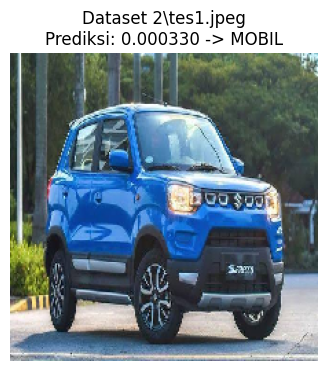

File: Dataset 2\tes1.jpeg
Nilai prediksi : 0.00033038356923498213
Hasil          : MOBIL



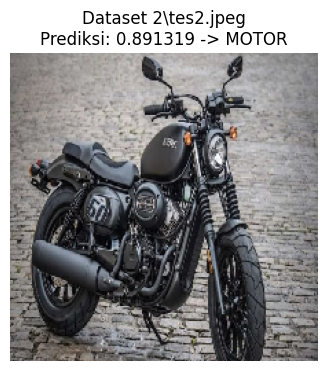

File: Dataset 2\tes2.jpeg
Nilai prediksi : 0.8913190960884094
Hasil          : MOTOR



In [3]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

loaded_model = load_model("model_motor_mobil.keras")

def uji_gambar(nama_file):
    if not os.path.exists(nama_file):
        alt_path = os.path.join("Dataset 2", nama_file)
        if os.path.exists(alt_path):
            nama_file = alt_path
    
    img_pil = image.load_img(nama_file, target_size=(224, 224))
    img_arr = image.img_to_array(img_pil) / 255.0
    img_input = np.expand_dims(img_arr, axis=0)

    hasil = loaded_model.predict(img_input, verbose=0)
    nilai = float(hasil[0][0])
    label = "MOTOR" if nilai >= 0.5 else "MOBIL"

    plt.figure(figsize=(4, 4))
    plt.imshow(img_pil)
    plt.title(f"{nama_file}\nPrediksi: {nilai:.6f} -> {label}")
    plt.axis('off')
    plt.show()

    print(f"File: {nama_file}")
    print(f"Nilai prediksi : {nilai}")
    print(f"Hasil          : {label}\n")

uji_gambar("tes1.jpeg")
uji_gambar("tes2.jpeg")